In [3]:
import os, sys
import numpy as np
import yaml
from tqdm import tqdm
from PIL import Image

# Add the project root directory to sys.path
project_root = os.path.abspath('..')  # Adjust this path if needed
sys.path.append(project_root)

from utils import get_images_from_directory, read_h5

2024-09-18 10:38:23.771349: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-09-18 10:38:23.785982: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-09-18 10:38:23.790443: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-09-18 10:38:23.804456: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-09-18 10:38:24.964059: W tensorflow/compiler/tf2

In [4]:
# Load the YAML file into a dictionary
dataset_yaml_file = '/workspace/home/data/datasets.yaml'
with open(dataset_yaml_file, 'r') as file:
    datasets = yaml.safe_load(file)

In [5]:
# get dataset
dataset_key = "ISIC2019"#'Pascal_VOC07' #
dataset = datasets[dataset_key]
id_tag = '0004'

# load the ground truth, predicted segmentations and images
segmentation_path = f"/workspace/home/data/{datasets[dataset_key]['dataset_dir']}/seg_dito/0004"
#segmentation_path = f"/workspace/home/data/{datasets[dataset_key]['dataset_dir']}/seg_groundedRMBG-1.4/{id_tag}"
segmentation_gt_path = datasets[dataset_key]['gt_seg_path']

segmentation_masks_confounder = get_images_from_directory(dir_path=segmentation_path) # might be wrong: filter with label
segmentation_masks_gt = get_images_from_directory(dir_path=segmentation_gt_path)

In [6]:
segmentation_masks_hint_path = "/workspace/datasets/ISIC19/cancer_masks_hint.h5"
segmentation_masks_hint_path2 = "/workspace/datasets/ISIC19/not_cancer_masks_hint.h5"
segmentation_masks_hint = read_h5(segmentation_masks_hint_path)
segmentation_masks_hint2 = read_h5(segmentation_masks_hint_path2)

print(segmentation_masks_hint["cancer_masks_hint"].shape)
print(segmentation_masks_hint2["not_cancer_masks_hint"].shape)

(2553, 1, 299, 299)
(19734, 1, 299, 299)


(299, 299)
0.0
0.0


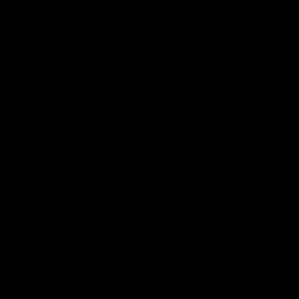

(299, 299)
0.0
0.0


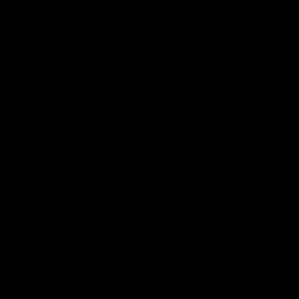

(299, 299)
0.0
0.0


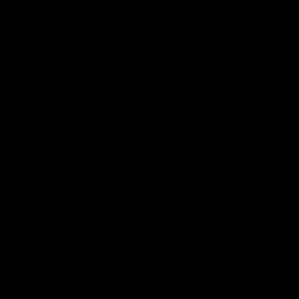

(299, 299)
0.0
0.0


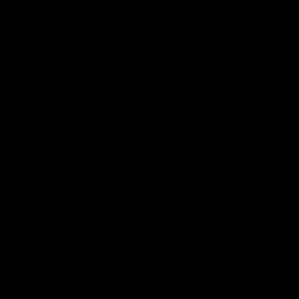

(299, 299)
0.0
0.0


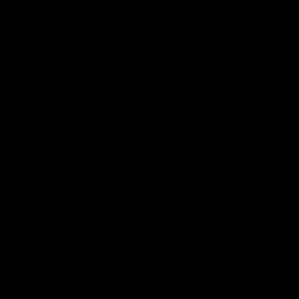

In [8]:
for i in range(5):
    mask = segmentation_masks_hint["cancer_masks_hint"][i]
    mask = np.squeeze(mask)
    print(mask.shape)
    print(mask.max())
    print(mask.min())
    mask_image = Image.fromarray((mask * 255).astype(np.uint8))
    mask_image.show()